# Project 2, Teach your webcam

**AI Fundamentals, Session 3**

Build your own image classifier in five minutes, with thirty examples per class and no
labelled dataset. Pick any distinction you can show to a camera:

- thumbs up, thumbs down, nothing: a silent vote in a meeting
- PMD, paper, rest: which Brussels bin does this go in?
- a mug, a phone, empty hands
- the door open, the door closed

You will:

- **A** Borrow the eyes of a network trained on 142 million images, and see what it sees
- **B** Record your own examples with the webcam
- **C** Train a classifier on them, in milliseconds
- **D** Run it live
- **E** Break it on purpose, and find out what it really learned

The point: the expensive part, learning to see, was done once by somebody else. You only
teach the last step. This is **transfer learning**, and it is how most real image systems
are built.

In [2]:
import cv2  # resizing images
import matplotlib.pyplot as plt  # plotting
import numpy as np  # arrays of numbers
import torch  # the deep learning library the network runs on
from PIL import Image  # opening image files
from transformers import AutoImageProcessor, AutoModel  # loads networks from Hugging Face

print("ready")

ready


---
## Part A, borrowed eyes

**DINOv2** is a vision network published by Meta. It learned from 142 million images
without a single label: it was only asked to give two crops of the same photo similar
numbers. What came out is a network that turns any image into 384 numbers, and similar
images get similar numbers.

The small version is 88 MB on Hugging Face. Two lines load it.

In [3]:
# The processor prepares an image the way the network expects: resized, cropped to 224 by
# 224 pixels and normalised. The model is the network itself.
processor = AutoImageProcessor.from_pretrained("facebook/dinov2-small")
network = AutoModel.from_pretrained("facebook/dinov2-small").eval()   # eval(): use, not train


def embed(image):
    """Turn one image into 384 numbers that describe what it shows."""
    inputs = processor(images=image, return_tensors="pt")   # "pt" asks for PyTorch tensors
    with torch.no_grad():                # we are not training, so skip the gradient bookkeeping
        output = network(**inputs)
    vector = output.pooler_output[0].numpy()        # the 384 numbers, as a numpy array
    return vector / np.linalg.norm(vector)          # scale to length 1, so we can compare


coffee = np.array(Image.open("data/images/coffee.jpg").convert("RGB"))
vector = embed(coffee)
print("one image becomes", vector.shape[0], "numbers. The first eight:")
print(vector[:8].round(3))

one image becomes 384 numbers. The first eight:
[ 0.133 -0.017  0.072 -0.035 -0.086 -0.079 -0.047  0.002]


384 numbers mean nothing to a person. What matters is how close two images land. We
compare them with the **cosine similarity**: 1 means pointing the same way, 0 means
unrelated. For vectors of length 1 it is simply the dot product, sum of the products of
matching numbers.

Below are five photos plus two edited copies of the coffee: mirrored and cropped, and turned
grey. To the network, are the copies still coffee?

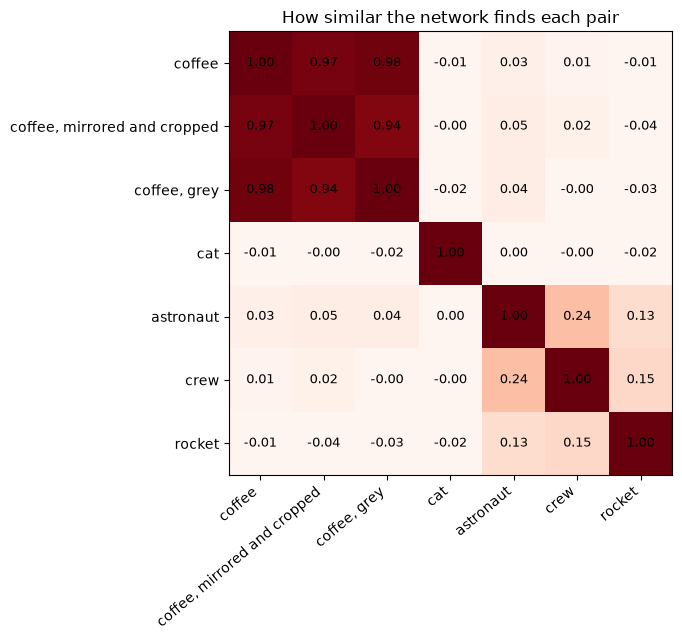

In [4]:
def load(name):
    return np.array(Image.open(f"data/images/{name}.jpg").convert("RGB"))


images = {
    "coffee": coffee,
    "coffee, mirrored and cropped": np.ascontiguousarray(coffee[60:340, ::-1][:, 80:520]),
    "coffee, grey": np.stack([coffee.mean(axis=2).astype(np.uint8)] * 3, axis=2),
    "cat": load("chelsea"),
    "astronaut": load("astronaut"),
    "crew": load("crew"),
    "rocket": load("rocket"),
}
names = list(images)
vectors = np.array([embed(img) for img in images.values()])   # one row per image
similarity = vectors @ vectors.T     # @ multiplies matrices: every row against every row

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.imshow(similarity, cmap="Reds", vmin=0, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=40, ha="right")
ax.set_yticks(range(len(names)), names)
for i in range(len(names)):              # write the number in every square
    for j in range(len(names)):
        ax.text(j, i, f"{similarity[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("How similar the network finds each pair")
plt.tight_layout()
plt.show()

Read the coffee rows first: the edited copies stay close to the original, much closer than
any other photo. Then the people: the astronaut is closer to the crew than to the cup. The
network was never told what a cup or a person is. It sorted the world by itself, and that
sorting is what you borrow.

---
## Part B, record your examples

The app below shows your webcam. Under it are three classes; rename them to whatever you
want to teach. Each **Add 30 examples** button records the next 30 frames as examples of
that class, which takes about three seconds. While it records, move a little: closer,
further, a bit to the side. Variety now is accuracy later.

1. Allow the camera and press **Record** under the webcam, so frames start flowing
2. Show the first thing, then press its **Add 30 examples** button
3. Do the same for the other classes. Twice per class is better than once

In [ ]:
import gradio as gr

FRAMES_PER_CLICK = 30
examples = {}                             # class name -> list of vectors, 384 numbers each
thumbnails = {}                           # class name -> a few small pictures, to look at later
recording = {"name": None, "left": 0}     # what the camera is recording right now


def status():
    """A short text for the app: what is being recorded, and how many examples we have."""
    now = f"Recording **{recording['name']}**, {recording['left']} to go" if recording["name"] else "Not recording"
    counts = "\n".join(f"- **{name}**: {len(v)} examples" for name, v in examples.items())
    return now + "\n\n" + (counts or "No examples yet")


def on_frame(frame):
    """Runs for every webcam frame. While a class is recording, keep the frame."""
    if frame is not None and recording["name"]:
        name = recording["name"]
        examples.setdefault(name, []).append(embed(frame))    # setdefault: start a list if new
        if len(thumbnails.setdefault(name, [])) < 8:
            thumbnails[name].append(cv2.resize(frame, (160, 120)))
        recording["left"] -= 1
        if recording["left"] == 0:
            recording["name"] = None                          # done: stop recording
    return status()


def start_recording(name):
    """Runs when you press a button: record the next frames under this name."""
    if name.strip():
        recording.update(name=name.strip(), left=FRAMES_PER_CLICK)
    return status()


with gr.Blocks(title="Teach your webcam") as collect_app:
    gr.Markdown("## Teach your webcam, step 1: examples")
    with gr.Row():
        camera = gr.Image(sources=["webcam"], streaming=True, label="Webcam")
        progress = gr.Markdown(status())
    for default in ["thumbs up", "thumbs down", "nothing"]:
        with gr.Row():
            name = gr.Textbox(value=default, show_label=False, scale=3)
            button = gr.Button(f"Add {FRAMES_PER_CLICK} examples", scale=1)
        button.click(start_recording, inputs=name, outputs=progress)
    camera.stream(on_frame, inputs=camera, outputs=progress, stream_every=0.1)

collect_app.launch(inbrowser=True, inline=False)

In [ ]:
# When you have recorded every class, stop the app and look at what you collected.
collect_app.close()

for name, vectors_of_class in examples.items():
    print(f"{name:<15} {len(vectors_of_class)} examples")

In [ ]:
# A few of the frames you recorded, one row per class.
fig, axes = plt.subplots(len(thumbnails), 8, figsize=(14, 1.9 * len(thumbnails)), squeeze=False)
for row, (name, pictures) in zip(axes, thumbnails.items()):
    for ax in row:
        ax.axis("off")
    for ax, picture in zip(row, pictures):
        ax.imshow(picture)
    row[0].set_title(name, loc="left")
plt.tight_layout()
plt.show()

---
## Part C, train the last step

Every example is now 384 numbers plus a name. That is exactly the kind of table you
trained models on in Session 2, so we use a model from Session 2: **logistic regression**.
The network stays frozen; only this small model on top learns.

In [ ]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# Keep only the classes with enough examples.
classes = [name for name, v in examples.items() if len(v) >= 5]
if len(classes) < 2:
    raise ValueError("Record at least 5 examples for at least two classes in Part B first.")

# X: one row per example, 384 columns. y: the class name of each row.
X = np.array([v for name in classes for v in examples[name]])
y = np.array([name for name in classes for _ in examples[name]])
print("table:", X.shape[0], "rows by", X.shape[1], "columns")

In [ ]:
# Before training anything: squeeze the 384 numbers down to 2 so we can draw them.
# PCA keeps the two directions in which the examples differ most.
points = PCA(n_components=2).fit_transform(X)

COLOURS = ["#E30613", "#3C3C3C", "#8C8C8C", "#F28B90", "#9B0A12"]   # EhB red, then greys and pinks

fig, ax = plt.subplots(figsize=(7, 5))
for colour, name in zip(COLOURS, classes):
    ax.scatter(*points[y == name].T, label=name, color=colour, alpha=0.7)   # y == name picks that class's rows
ax.legend()
ax.set_title("Your examples, as the network sees them")
plt.show()

If the colours already form separate clouds, the network's numbers alone tell your classes
apart, and the classifier only has to draw the lines between the clouds. Overlapping
clouds mean the network does not see the difference you care about. More examples will not
fix that; more *varied* examples might.

In [ ]:
# The same honest procedure as in Session 2: keep a quarter of the examples back for testing.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

classifier = LogisticRegression(max_iter=2000)
classifier.fit(X_train, y_train)          # this is the whole training, a few milliseconds

print("training accuracy:", accuracy_score(y_train, classifier.predict(X_train)))
print("test accuracy    :", accuracy_score(y_test, classifier.predict(X_test)))

You will probably see 1,0 on both, and you should not believe it. Your test frames were
recorded in the same three seconds as your training frames, a tenth of a second apart,
so they are near copies. The test only proves the model remembers those three seconds.

The honest test is a new situation: a different position, other light, another person.
That is Part D.

---
## Part D, live

In [ ]:
def predict(frame):
    """Runs for every webcam frame: the probability of each class."""
    if frame is None:
        return {}
    probabilities = classifier.predict_proba([embed(frame)])[0]
    # gr.Label wants a dictionary {class name: probability}; zip pairs them up.
    return {name: float(p) for name, p in zip(classifier.classes_, probabilities)}


with gr.Blocks(title="Teach your webcam, live") as live_app:
    gr.Markdown("## Teach your webcam, step 2: live")
    with gr.Row():
        camera = gr.Image(sources=["webcam"], streaming=True, label="Webcam")
        answer = gr.Label(num_top_classes=3, label="What it sees")
    camera.stream(predict, inputs=camera, outputs=answer, stream_every=0.1)

live_app.launch(inbrowser=True, inline=False)

---
## Part E, break it on purpose

Keep the live app open and try to fool your own model. Each of these tests one thing it
might have learned instead of what you meant:

1. **Position.** Do your thumbs up in a corner of the picture, far from where you recorded it
2. **Light.** Switch a lamp on or off, or turn your back to the window
3. **Background.** Stand up, or move the laptop so the wall behind you changes
4. **Person.** Let your neighbour try your model
5. **Nothing.** Does *nothing* still work when you are not in the picture at all?

Whenever it fails, ask what was different in all your recordings of one class and not the
others. That difference, not your thumb, may be what it learned: the easiest cue that
separates the examples, exactly as in the lecture.

**Exercise E1.** Find one failure, then fix it by recording more examples in the
situation that failed (Part B again: the app adds to the examples you already have). Train
again (Part C) and test again.

**Exercise E2.** How few examples do you need? Change `FRAMES_PER_CLICK` to 5 and repeat.

**Exercise E3.** Add a fourth class. Does it confuse the other three?

In [ ]:
live_app.close()

---
## What to take from this

**Transfer learning is the default.** Training DINOv2 took Meta thousands of GPU hours.
Reusing it took you two lines, and your own part trained in milliseconds on 90 examples.
Most image systems in companies are built like this: a large borrowed network and a small
model on top.

**Your examples define what it learns.** The model learns whatever separates your classes
most easily, and you only find out by testing it somewhere new. The cure is not a bigger
model; it is examples that differ in everything except the thing you care about.

**What not to build.** A model that reads emotions from faces is easy to train this way.
In a school or a workplace it is also prohibited: the EU AI Act bans emotion recognition in
education and employment, apart from medical and safety reasons.

Images from the scikit-image sample data: coffee by Rachel Michetti and cat by Stéfan van
der Walt, both CC0; astronaut and rocket, NASA, public domain. Crew: Expedition 64, NASA,
public domain.